Saving CNN_Dataset.csv to CNN_Dataset.csv
   label  pixel_00  pixel_01  pixel_02  pixel_03  pixel_04  pixel_05  \
0      0       0.0       0.0       5.0      13.0       9.0       1.0   
1      1       0.0       0.0       0.0      12.0      13.0       5.0   
2      2       0.0       0.0       0.0       4.0      15.0      12.0   
3      3       0.0       0.0       7.0      15.0      13.0       1.0   
4      4       0.0       0.0       0.0       1.0      11.0       0.0   
5      5       0.0       0.0      12.0      10.0       0.0       0.0   
6      6       0.0       0.0       0.0      12.0      13.0       0.0   
7      7       0.0       0.0       7.0       8.0      13.0      16.0   
8      8       0.0       0.0       9.0      14.0       8.0       1.0   
9      9       0.0       0.0      11.0      12.0       0.0       0.0   

   pixel_06  pixel_07  pixel_08  ...  pixel_54  pixel_55  pixel_56  pixel_57  \
0       0.0       0.0       0.0  ...       0.0       0.0       0.0       0.0   
1    

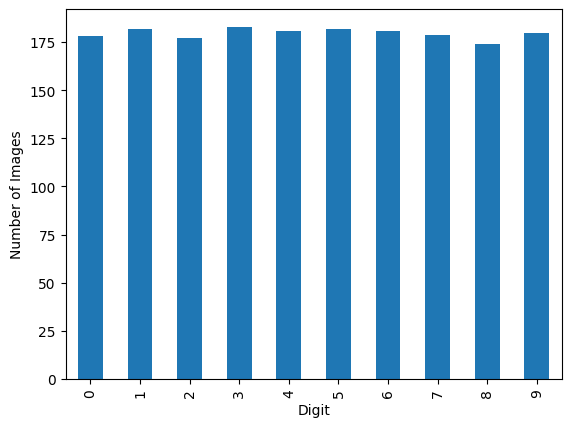

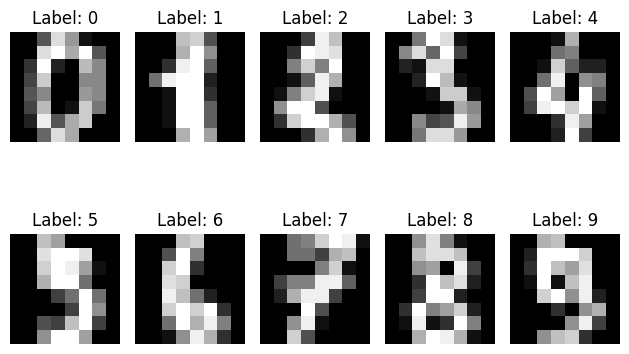

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
uploaded = files.upload()


df = pd.read_csv(next(iter(uploaded)))

print(df.head(10))
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())

print("Class distribution:")
print(df['label'].value_counts().sort_index())

df['label'].value_counts().sort_index().plot(kind='bar')
plt.xlabel("Digit")
plt.ylabel("Number of Images")
plt.show()

# Display sample images
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(df.iloc[i, 1:].values.reshape(8, 8), cmap='gray')
    plt.title("Label: " + str(df.iloc[i, 0]))
    plt.axis('off')

plt.tight_layout()
plt.show()

Training images: (1257, 32, 32, 1)
Testing images: (540, 32, 32, 1)


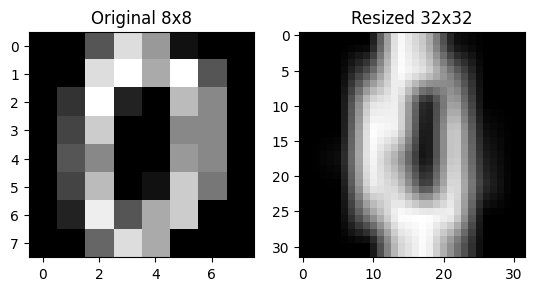

In [ ]:
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

X = df.drop('label', axis=1).values
y = df['label'].values

# Convert pixels to range 0–1
X = X / 16.0

# Reshape into 8x8 grayscale images
X = X.reshape(-1, 8, 8, 1)

# Resize images to 32x32
X = tf.image.resize(X, (32, 32)).numpy()

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

plt.subplot(1, 2, 1)
plt.imshow(df.iloc[0, 1:].values.reshape(8, 8), cmap='gray')
plt.title("Original 8x8")

plt.subplot(1, 2, 2)
plt.imshow(X_train[0].squeeze(), cmap='gray')
plt.title("Resized 32x32")
plt.show()

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense

model = Sequential([
    Input(shape=(32, 32, 1)),
    Conv2D(16, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,242 (309.54 KB)

 Trainable params: 79,242 (309.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 117ms/step - accuracy: 0.2766 - loss: 2.1556 - val_accuracy: 0.4008 - val_loss: 1.8973
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.7284 - loss: 1.3923 - val_accuracy: 0.8373 - val_loss: 0.8142
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 85ms/step - accuracy: 0.8706 - loss: 0.5441 - val_accuracy: 0.8770 - val_loss: 0.3877
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 106ms/step - accuracy: 0.9095 - loss: 0.3086 - val_accuracy: 0.9167 - val_loss: 0.2704
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 103ms/step - accuracy: 0.9244 - loss: 0.2459 - val_accuracy: 0.9405 - val_loss: 0.2220
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 101ms/step - accuracy: 0.9413 - loss: 0.1830 - val_accuracy: 0.9286 - val_loss: 0.1941
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 93ms/step - accuracy: 0.9552 - loss: 0.1371 - val_accuracy: 0.9524 - val_loss: 0.1440
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 88ms/step - accuracy: 0.9701 - loss: 0.1130 - val_accuracy: 0.9444

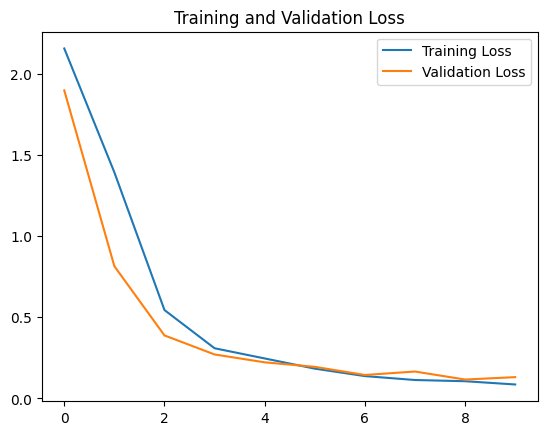

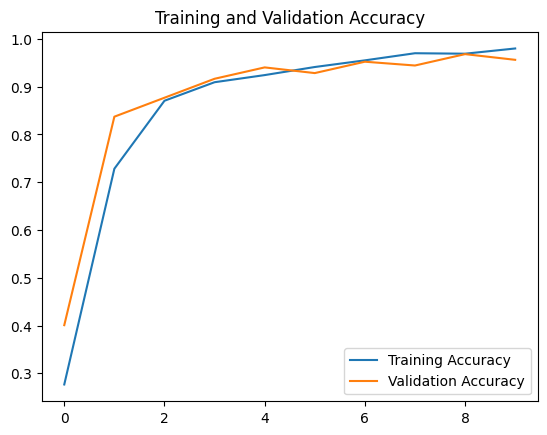

In [ ]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title("Training and Validation Accuracy")
plt.legend()
plt.show()

17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step
Accuracy: 0.9537037037037037
Precision: 0.9579864626898524
Recall: 0.9530912658271149
F1-score: 0.9538351841786084
              precision    recall  f1-score   support

           0       1.00      0.98      0.99        54
           1       0.82      0.98      0.89        55
           2       1.00      0.92      0.96        53
           3       1.00      0.98      0.99        55
           4       0.95      0.98      0.96        54
           5       1.00      0.95      0.97        55
           6       1.00      0.96      0.98        54
           7       0.92      1.00      0.96        54
           8       0.96      0.83      0.89        52
           9       0.94      0.94      0.94        54

    accuracy                           0.95       540
   macro avg       0.96      0.95      0.95       540
weighted avg       0.96      0.95      0.95       540



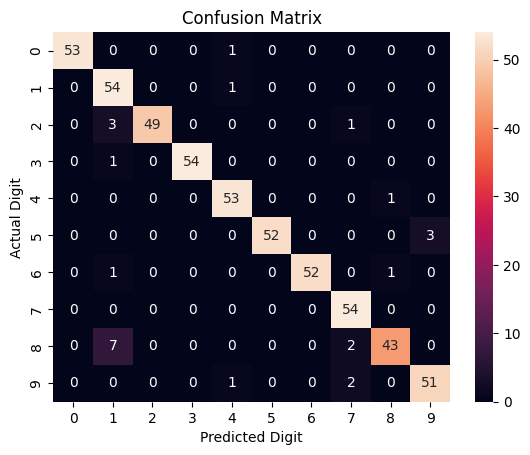

In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

probabilities = model.predict(X_test)
pred = np.argmax(probabilities, axis=1)

print("Accuracy:", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred, average='macro'))
print("Recall:", recall_score(y_test, pred, average='macro'))
print("F1-score:", f1_score(y_test, pred, average='macro'))

print(classification_report(y_test, pred))

sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d')
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("Confusion Matrix")
plt.show()

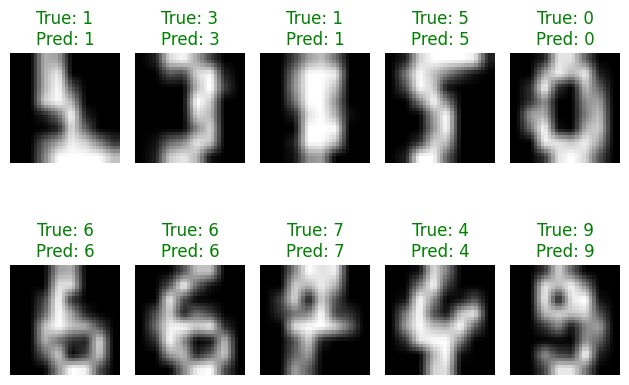

Probabilities for first image: [1.3047335e-07 9.8565543e-01 9.9088138e-05 3.9798786e-05 7.7455264e-04
 6.6611953e-03 4.3013389e-03 2.4751923e-08 2.4112796e-03 5.7126308e-05]


In [ ]:
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i].squeeze(), cmap='gray')

    color = 'green' if pred[i] == y_test[i] else 'red'
    plt.title(f"True: {y_test[i]}\nPred: {pred[i]}", color=color)
    plt.axis('off')

plt.tight_layout()
plt.show()

print("Probabilities for first image:", probabilities[0])

In [ ]:
import time

def build_cnn(simple=False):
    if simple:
        net = Sequential([
            Input(shape=(32, 32, 1)),
            Conv2D(16, (3, 3), activation='relu'),
            MaxPooling2D((2, 2)),
            Flatten(),
            Dense(64, activation='relu'),
            Dense(10, activation='softmax')
        ])
    else:
        net = Sequential([
            Input(shape=(32, 32, 1)),
            Conv2D(16, (3, 3), activation='relu'),
            MaxPooling2D((2, 2)),
            Conv2D(32, (3, 3), activation='relu'),
            MaxPooling2D((2, 2)),
            Flatten(),
            Dense(64, activation='relu'),
            Dense(10, activation='softmax')
        ])

    net.compile(optimizer='adam',
                loss='sparse_categorical_crossentropy',
                metrics=['accuracy'])
    return net

results = []

for simple in [True, False]:
    net = build_cnn(simple)

    start = time.time()
    net.fit(X_train, y_train, epochs=5,
            batch_size=64, verbose=0)
    duration = time.time() - start

    p = np.argmax(net.predict(X_test, verbose=0), axis=1)

    results.append({
        'Architecture': 'One Conv Layer' if simple else 'Two Conv Layers',
        'Accuracy': accuracy_score(y_test, p),
        'Macro F1': f1_score(y_test, p, average='macro'),
        'Training Time (seconds)': round(duration, 2)
    })

print(pd.DataFrame(results))

      Architecture  Accuracy  Macro F1  Training Time (seconds)
0   One Conv Layer  0.946296  0.946380                     7.52
1  Two Conv Layers  0.929630  0.929465                    11.36


In [ ]:
from tensorflow.keras.layers import Reshape

dense_model = Sequential([
    Input(shape=(32, 32, 1)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

dense_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

dense_model.fit(X_train, y_train, epochs=10,
                batch_size=64, verbose=1)

dense_pred = np.argmax(dense_model.predict(X_test), axis=1)

print("CNN Accuracy:", accuracy_score(y_test, pred))
print("Dense Network Accuracy:", accuracy_score(y_test, dense_pred))
print("CNN Macro F1:", f1_score(y_test, pred, average='macro'))
print("Dense Macro F1:", f1_score(y_test, dense_pred, average='macro'))

Epoch 1/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.6388 - loss: 1.4820
Epoch 2/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8783 - loss: 0.5111
Epoch 3/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9332 - loss: 0.2808
Epoch 4/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9451 - loss: 0.2084
Epoch 5/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9539 - loss: 0.1747
Epoch 6/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9602 - loss: 0.1422
Epoch 7/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9698 - loss: 0.1240
Epoch 8/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9706 - loss: 0.1178
Epoch 9/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9650 - loss: 0.1166
Epoch 10/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9769 - loss: 0.0850
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
CNN Accuracy: 0.9537037037037037
Dense Network Accuracy: 0.95
CNN Macro F1: 0.9538351841786084
Dense Macro F1: 0.9

In [ ]:
print("Total images:", len(df))
print("Image size used:", "32 x 32")
print("Number of classes:", df['label'].nunique())
print("CNN Test Accuracy:", accuracy_score(y_test, pred))
print("CNN Macro Precision:", precision_score(y_test, pred, average='macro'))
print("CNN Macro Recall:", recall_score(y_test, pred, average='macro'))
print("CNN Macro F1:", f1_score(y_test, pred, average='macro'))

Total images: 1797
Image size used: 32 x 32
Number of classes: 10
CNN Test Accuracy: 0.9537037037037037
CNN Macro Precision: 0.9579864626898524
CNN Macro Recall: 0.9530912658271149
CNN Macro F1: 0.9538351841786084
